In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

X_train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML vežbe/dataset_houseprices/X_train.csv')
X_test = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML vežbe/dataset_houseprices/X_test.csv')

y_train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML vežbe/dataset_houseprices/y_train.csv')
y_test = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML vežbe/dataset_houseprices/y_test.csv')

In [ ]:
X_train.shape, X_test.shape

((1168, 77), (146, 77))

In [ ]:
X_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Utilities,LandSlope,Neighborhood,Condition2,...,YrSold_sub_GarageYrBlt,YearRemodAdd_sub_YearBuilt,LotFrontage_na,MasVnrArea_na,YrSold_sub_GarageYrBlt_na,GarageCars_na,BsmtFullBath_na,BsmtHalfBath_na,BsmtBath_total,Bath_total
0,255,2,1,70.0,8400,1,1,0,2,1,...,53.0,0,0,0,0,0,0,0,1,1
1,1067,4,1,59.0,7837,1,1,0,5,1,...,16.0,1,0,0,0,0,0,0,0,3
2,639,1,1,67.0,8777,1,1,0,0,1,...,27.5,40,0,0,1,0,0,0,0,1
3,800,0,1,60.0,7200,1,1,0,3,1,...,68.0,13,0,0,0,0,0,0,1,2
4,381,0,1,50.0,5000,1,1,0,3,1,...,86.0,26,0,0,0,0,0,0,0,2


In [ ]:
feature_names = list(X_train.columns)
feature_names.remove('Id')

# Recreate the DataFrame without the 'Id' column
X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)

In [ ]:
X_train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Utilities,LandSlope,Neighborhood,Condition2,OverallQual,...,YrSold_sub_GarageYrBlt,YearRemodAdd_sub_YearBuilt,LotFrontage_na,MasVnrArea_na,YrSold_sub_GarageYrBlt_na,GarageCars_na,BsmtFullBath_na,BsmtHalfBath_na,BsmtBath_total,Bath_total
0,2,1,70.0,8400,1,1,0,2,1,5,...,53.0,0,0,0,0,0,0,0,1,1
1,4,1,59.0,7837,1,1,0,5,1,6,...,16.0,1,0,0,0,0,0,0,0,3
2,1,1,67.0,8777,1,1,0,0,1,5,...,27.5,40,0,0,1,0,0,0,0,1
3,0,1,60.0,7200,1,1,0,3,1,5,...,68.0,13,0,0,0,0,0,0,1,2
4,0,1,50.0,5000,1,1,0,3,1,5,...,86.0,26,0,0,0,0,0,0,0,2


# Normalize the data

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler to the training data only, then transform the training data
X_train = scaler.fit_transform(X_train)

# Use the same scaler to transform the test set
X_test = scaler.transform(X_test)

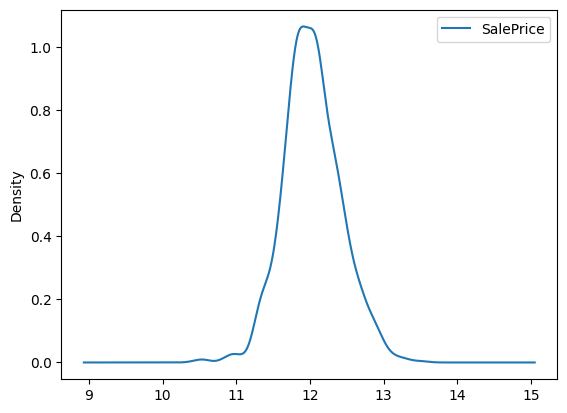

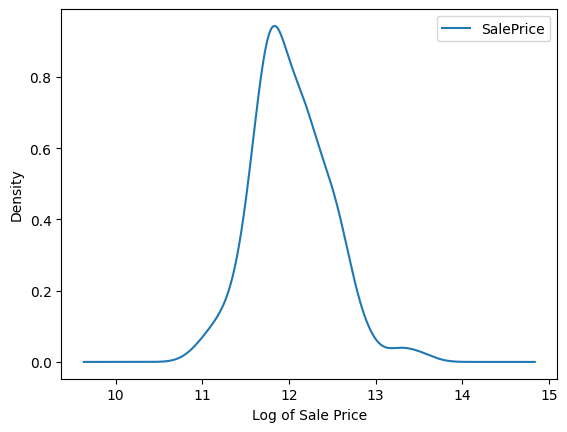

In [ ]:
import matplotlib.pyplot as plt

y_train.plot.density()
y_test.plot.density()

plt.xlabel('Log of Sale Price')
plt.show()

# Utility functions

## Evaluacija modela:

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    return rmse, r2

## Iscrtavanje vrednosti trening i validacione greške naspram vrednosti koeficijenta (theta)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_train_val_errors(grid_search_cv, y_axis_limits):
  mean_train_scores = np.sqrt(-grid_search_cv.cv_results_['mean_train_score'])
  mean_test_scores = np.sqrt(-grid_search_cv.cv_results_['mean_test_score'])
  alphas = grid_search_cv.cv_results_['param_alpha']
  best_alpha = grid_search_cv.best_estimator_.alpha

  plt.figure(figsize=(10, 6))
  plt.plot(alphas, mean_train_scores, label='Training Error', color='blue', marker='o', linestyle='--')
  plt.plot(alphas, mean_test_scores, label='Test Error', color='red', marker='x')
  plt.ylim([y_axis_limits[0], y_axis_limits[1]])

  # Add a vertical line at the optimal hyperparameter value
  plt.axvline(x=best_alpha, color='grey', linestyle='--', linewidth=1)
  plt.text(best_alpha, plt.ylim()[1], 'Optimal\nAlpha', color='grey', fontsize=10, verticalalignment='top', horizontalalignment='center')

  plt.title('Training and Validation Errors for Different Alpha Values')
  plt.xlabel('Alpha')
  plt.ylabel('RMSE')
  plt.legend()
  plt.xscale('log')  # Use logarithmic scale if alphas vary over several orders of magnitude
  plt.grid(True)
  plt.show()

## Iscrtavanje vrednosti koeficijenata (theta) sa kojima se množe ulazi (X) u zavisnosti od regresionog koeficijenta (alpha).

In [ ]:
import matplotlib.pyplot as plt

# models - lista modela, npr. lista ridge modela treniranih koristeći različite regularizacione parametre alpha
# labels - labela grafika, npr. ['Ridge']
# hyperparams - lista vrednost hiperparametara (npr. lista vrednosti alpha koje korespondiraju modelima iz models)
# feature_names - imena obeležja, neophodna radi iscrtavanja legende
# best_alpha - najbolja vrednost alpha određena na validacionim podacima (radi označavanja linije na grafiku)
def plot_coefficients(models, labels, hyperparams, feature_names, best_alpha):
    plt.figure(figsize=(15, 10))

    for model_list, label in zip(models, labels):
        for i, feature_name in enumerate(feature_names):
            # Check the shape of the coefficients and adjust accordingly
            coeffs = []
            for model in model_list:
                if model.coef_.ndim == 1:
                    coeffs.append(model.coef_[i])
                else:  # For models where coef_ is a 2D array
                    coeffs.append(model.coef_[0, i])

            # Plot each feature's coefficients and get the line object
            line = plt.plot(hyperparams, coeffs, label=f"{label} - {feature_name}")[0]

            # Place the feature name text at the beginning of the line in the same color
            plt.text(hyperparams[0], coeffs[0], feature_name, color=line.get_color(), fontsize=9,
                     verticalalignment='center', horizontalalignment='right')

    # Add a vertical line at the optimal hyperparameter value
    plt.axvline(x=best_alpha, color='grey', linestyle='--', linewidth=1)
    plt.text(best_alpha, plt.ylim()[1], 'Optimal\nAlpha', color='grey', fontsize=10,
             verticalalignment='top', horizontalalignment='center')

    plt.xscale('log')  # Set x-axis to log scale for better visualization
    plt.xlabel('Hyperparameter value')
    plt.ylabel('Coefficient value')
    plt.title('Coefficients across different hyperparameters')
    plt.show()

## Vrednosti alpha parametra koje ćemo isprobati za sve tipove regresije

In [ ]:
# Selecting few values for alpha
range1= [0, 0.0001, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
range2= list(range(2, 1001))
range1.extend(range2)
alphas = range1

# Linear Regression without regularization

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

lin_rmse_train, lin_r2_train = evaluate_model(lin_reg, X_train, y_train)
lin_rmse, lin_r2 = evaluate_model(lin_reg, X_test, y_test)

print(f"Linear Regression Train - RMSE: {lin_rmse_train:.3f}, R²: {lin_r2_train:.3f}")
print(f"Linear Regression Test - RMSE: {lin_rmse:.3f}, R²: {lin_r2:.3f}")

Linear Regression Train - RMSE: 0.129, R²: 0.890
Linear Regression Test - RMSE: 0.132, R²: 0.909


In [ ]:
# Model coefficients
lin_reg.coef_

array([[ 2.59461747e-03,  1.21309337e-03, -2.45120622e-03,
         1.50831734e-02,  3.55724393e-03,  1.03993510e-02,
         6.47610251e-04,  7.67255317e-03,  9.10859123e-03,
         8.05357047e-02,  4.36743052e-02, -7.16982857e-03,
         2.41043462e-02, -2.47324116e-02, -7.22425769e-03,
        -8.87904206e-04,  4.83199182e-03, -2.96597759e-03,
         1.56016356e-02,  1.56798996e-02, -1.18288784e-03,
         1.56719683e-02,  1.73411981e-02, -1.10585388e+10,
        -8.04881500e-03, -3.81129375e+09, -1.07524543e+10,
         1.06154310e+10, -4.74392786e-03,  1.62915972e-02,
         1.47379239e-02,  2.59447332e+10,  2.94938673e+10,
         3.21307900e+09, -3.51878366e+10,  5.38910013e+09,
         2.44896448e+09, -3.84801884e+10, -3.51761771e+10,
         9.49263573e-03, -1.35145187e-02,  1.69217587e-02,
         2.66475677e-02,  1.57451630e-03,  2.14014053e-02,
         4.84943390e-03,  9.97543335e-03,  4.47201729e-02,
         1.40414238e-02,  4.82740402e-02, -1.56397820e-0

In [ ]:
# Ridge intercept
lin_reg.intercept_

array([12.03065114])

# Ridge regression

### Određivanje najboljeg alpha unakrsnom validacijom

In [ ]:
from sklearn.model_selection import GridSearchCV

ridge= Ridge(random_state= 42)
params_grid= {'alpha': range1}

gcv_ridge= GridSearchCV(estimator= ridge,
                        param_grid= params_grid,
                        cv=5,
                        scoring= 'neg_mean_squared_error',
                        return_train_score= True,
                        n_jobs= -1,
                        verbose= 1)
gcv_ridge.fit(X_train, y_train)

print("Ridge best alpha: ", gcv_ridge.best_estimator_.alpha)

Fitting 5 folds for each of 1014 candidates, totalling 5070 fits
Ridge best alpha:  296


Iscrtavanje train i validation greške radi provere:

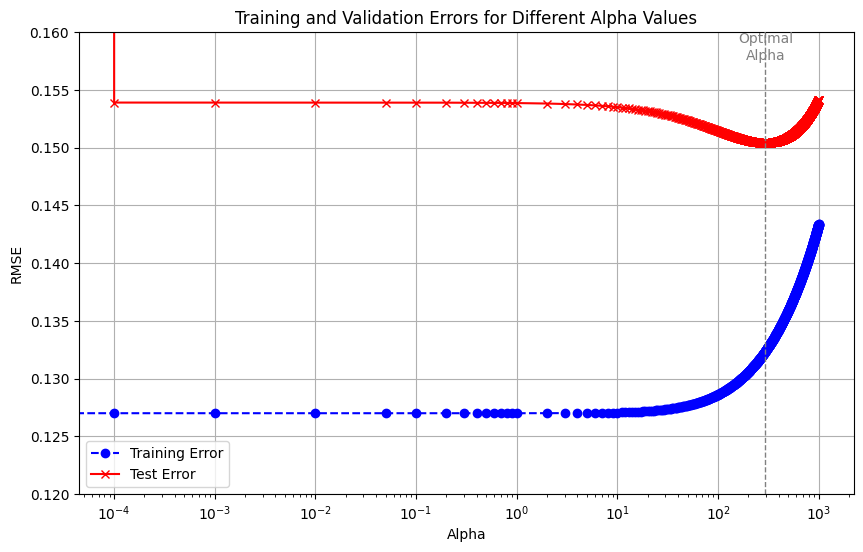

In [ ]:
plot_train_val_errors(gcv_ridge, [0.12, 0.16])

### Iscrtavanje vrednosti koeficijenata ridge modela naspram vrednosti alpha

In [ ]:
gcv_ridge.best_estimator_.alpha

296

In [ ]:
alphas_subset = np.linspace(0.1, 1000, num=10)

ridge_models = [Ridge(alpha=alpha).fit(X_train, y_train) for alpha in alphas_subset]

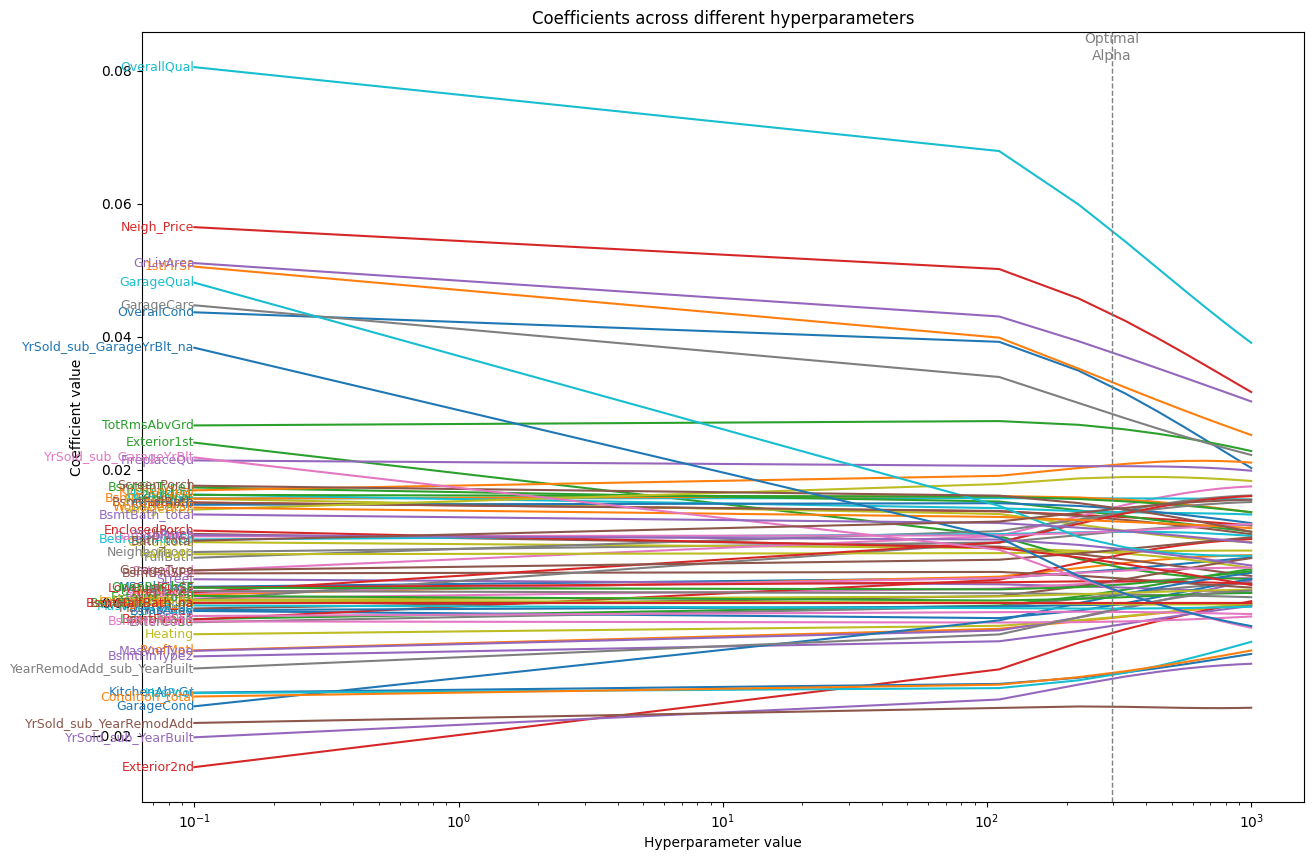

In [ ]:
plot_coefficients([ridge_models],
                  ['Ridge'],
                  alphas_subset,
                  feature_names,
                  gcv_ridge.best_estimator_.alpha)

### Evaluacija najboljeg ridge modela na test skupu:

In [ ]:
# Fitting model using best_estimator_
ridge_model= gcv_ridge.best_estimator_
ridge_model.fit(X_train, y_train)

ridge_rmse, ridge_r2 = evaluate_model(ridge_model, X_test, y_test)

print(f"Linear Regression - RMSE: {lin_rmse:.3f}, R²: {lin_r2:.3f}")
print(f"Ridge - RMSE: {ridge_rmse:.3f}, R²: {ridge_r2:.3f}, alpha: {gcv_ridge.best_estimator_.alpha}")

Linear Regression - RMSE: 0.132, R²: 0.909
Ridge - RMSE: 0.135, R²: 0.905, alpha: 296


## Najbitnija obeležja

In [ ]:
ridge_coef = pd.Series(ridge_model.coef_.flatten(), index=feature_names)
top_25_ridge = ridge_coef[abs(ridge_coef).nlargest(25).index]
print(top_25_ridge)

OverallQual                0.055999
Neigh_Price                0.043435
GrLivArea                  0.037661
1stFlrSF                   0.033208
OverallCond                0.032541
GarageCars                 0.028407
TotRmsAbvGrd               0.026301
KitchenQual                0.020715
FireplaceQu                0.020536
GarageArea                 0.018872
BsmtQual                   0.015691
YrSold_sub_YearRemodAdd   -0.015625
BsmtExposure               0.015619
2ndFlrSF                   0.015367
ScreenPorch                0.014360
CentralAir                 0.014238
ExterQual                  0.014224
Bath_total                 0.014053
HeatingQC                  0.013647
TotalBsmtSF                0.013403
BsmtFinType1               0.013279
FullBath                   0.013226
Fireplaces                 0.013004
LotArea                    0.012975
BsmtFullBath               0.012637
dtype: float64


In [ ]:
# Model coefficients
ridge_model.coef_

array([[ 0.00492569,  0.0057647 ,  0.00164448,  0.01297543,  0.00233606,
         0.00674727,  0.00305168,  0.01063827,  0.00753369,  0.05599947,
         0.03254147, -0.00228725,  0.00554026, -0.00455654, -0.00125952,
         0.00320893,  0.01422412,  0.00116939,  0.01107361,  0.0156907 ,
        -0.0004293 ,  0.01561873,  0.01327856,  0.00695631, -0.00349214,
         0.00374738,  0.00474922,  0.01340263, -0.00220679,  0.01364726,
         0.01423809,  0.03320841,  0.01536669,  0.00323515,  0.03766077,
         0.01263725, -0.00284585,  0.01322641,  0.00767185,  0.01066382,
        -0.01073651,  0.02071511,  0.02630066,  0.01300353,  0.02053638,
         0.00786468,  0.01071215,  0.02840743,  0.01887153,  0.00869849,
         0.00092917,  0.01225749,  0.00263138,  0.00611124,  0.00823504,
         0.01436   , -0.0013659 ,  0.00127496,  0.00142734, -0.0108977 ,
        -0.00027924, -0.01058038,  0.00075193,  0.04343451, -0.01143584,
        -0.01562541,  0.00201705, -0.00109874, -0.0

# LASSO regression

### Određivanje najboljeg alpha unakrsnom validacijom

In [ ]:
from sklearn.model_selection import GridSearchCV

lasso= Lasso(random_state= 42)
params_grid= {'alpha': range1}

gcv_lasso= GridSearchCV(estimator= lasso,
                        param_grid= params_grid,
                        cv=5,
                        scoring= 'neg_mean_squared_error',
                        return_train_score= True,
                        n_jobs= -1,
                        verbose= 1)
gcv_lasso.fit(X_train, y_train)

print("lasso best alpha: ", gcv_lasso.best_estimator_.alpha)

Fitting 5 folds for each of 313 candidates, totalling 1565 fits
lasso best alpha:  0.01


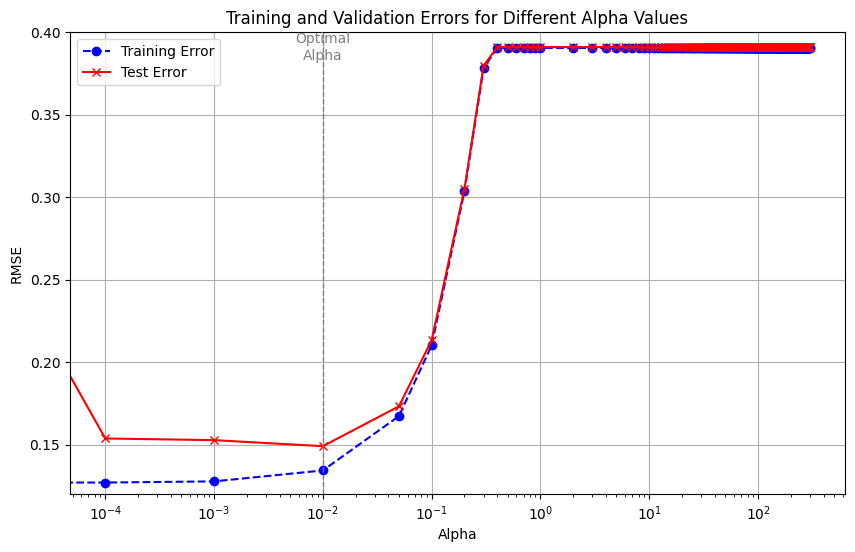

In [ ]:
plot_train_val_errors(gcv_lasso, [0.12, 0.4])

### Iscrtavanje vrednosti koeficijenata ridge modela naspram vrednosti alpha

In [ ]:
alphas_subset = np.linspace(0.001, 1000, num=10)

lasso_models = [Lasso(alpha=alpha).fit(X_train, y_train) for alpha in alphas_subset]

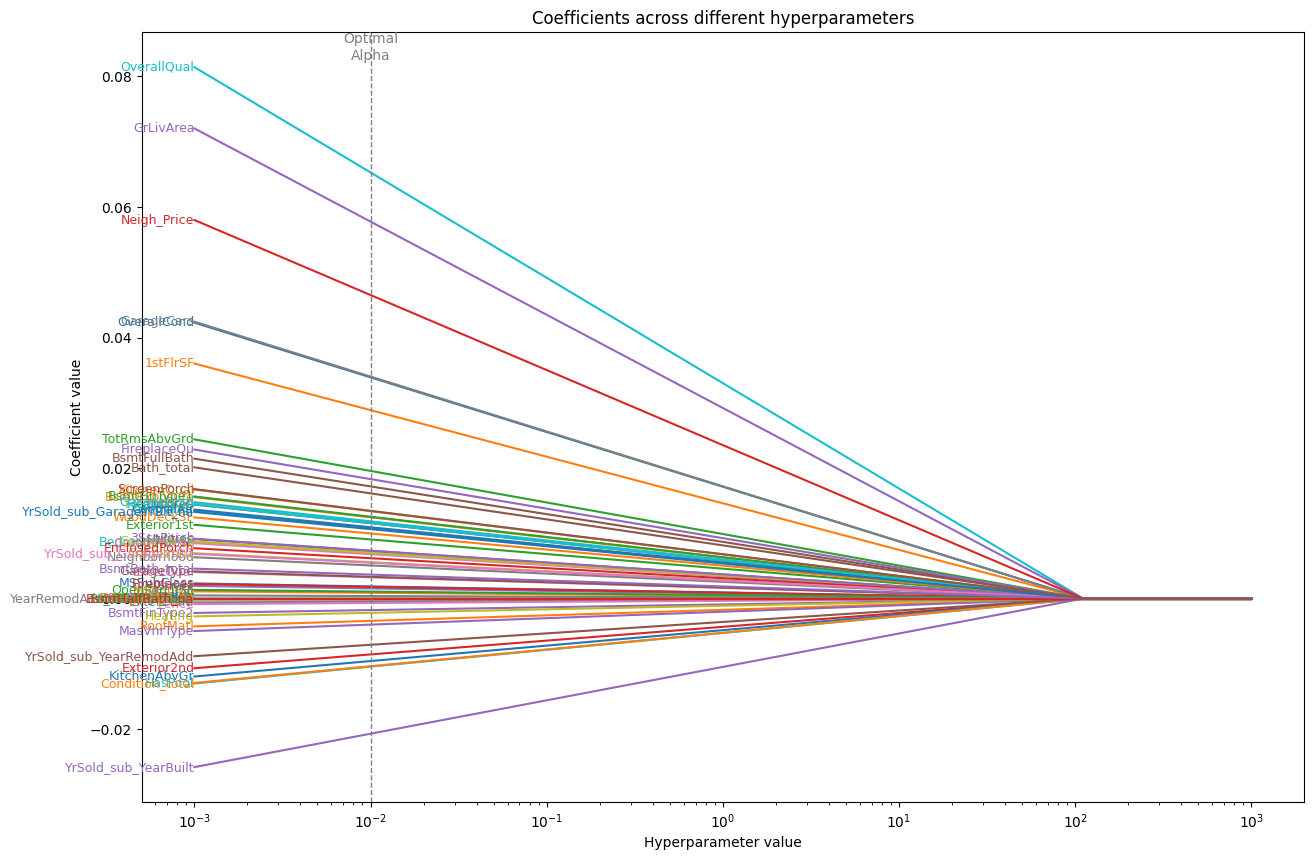

In [ ]:
plot_coefficients([lasso_models],
                  ['Lasso'],
                  alphas_subset,
                  feature_names,
                  gcv_lasso.best_estimator_.alpha)

### Evaluacija najboljeg LASSO modela na test skupu

In [ ]:
# Fitting model using best_estimator_
lasso_model= gcv_lasso.best_estimator_
lasso_model.fit(X_train, y_train)

lasso_rmse, lasso_r2 = evaluate_model(lasso_model, X_test, y_test)

print(f"Linear Regression - RMSE: {lin_rmse:.3f}, R²: {lin_r2:.3f}")
print(f"Ridge - RMSE: {ridge_rmse:.3f}, R²: {ridge_r2:.3f}, alpha: {gcv_ridge.best_estimator_.alpha}")
print(f"LASSO - RMSE: {lasso_rmse:.3f}, R²: {lasso_r2:.3f}, alpha: {gcv_lasso.best_estimator_.alpha}")

Linear Regression - RMSE: 0.132, R²: 0.909
Ridge - RMSE: 0.135, R²: 0.905, alpha: 296
LASSO - RMSE: 0.142, R²: 0.895, alpha: 0.01


### Najbitnija obeležja

In [ ]:
ridge_coef = pd.Series(ridge_model.coef_.flatten(), index=feature_names)
top_25_ridge = ridge_coef[abs(ridge_coef).nlargest(25).index]
print(top_25_ridge)

OverallQual                0.055999
Neigh_Price                0.043435
GrLivArea                  0.037661
1stFlrSF                   0.033208
OverallCond                0.032541
GarageCars                 0.028407
TotRmsAbvGrd               0.026301
KitchenQual                0.020715
FireplaceQu                0.020536
GarageArea                 0.018872
BsmtQual                   0.015691
YrSold_sub_YearRemodAdd   -0.015625
BsmtExposure               0.015619
2ndFlrSF                   0.015367
ScreenPorch                0.014360
CentralAir                 0.014238
ExterQual                  0.014224
Bath_total                 0.014053
HeatingQC                  0.013647
TotalBsmtSF                0.013403
BsmtFinType1               0.013279
FullBath                   0.013226
Fireplaces                 0.013004
LotArea                    0.012975
BsmtFullBath               0.012637
dtype: float64


In [ ]:
lasso_coef = pd.Series(lasso_model.coef_.flatten(), index=feature_names)
top_25_lasso = lasso_coef[abs(lasso_coef).nlargest(25).index]
print(top_25_lasso)

OverallQual                0.087410
GrLivArea                  0.078256
Neigh_Price                0.063139
GarageCars                 0.043768
OverallCond                0.027473
1stFlrSF                   0.027260
FireplaceQu                0.021722
KitchenQual                0.017298
BsmtFullBath               0.017298
BsmtQual                   0.016133
Bath_total                 0.015888
TotRmsAbvGrd               0.015860
BsmtFinType1               0.014734
CentralAir                 0.014269
HeatingQC                  0.013301
YrSold_sub_YearBuilt      -0.012904
BsmtExposure               0.011911
YrSold_sub_YearRemodAdd   -0.011815
GarageType                 0.010376
LotArea                    0.009173
GarageFinish               0.008103
Foundation                 0.007670
ScreenPorch                0.006528
WoodDeckSF                 0.006418
GarageArea                 0.005568
dtype: float64


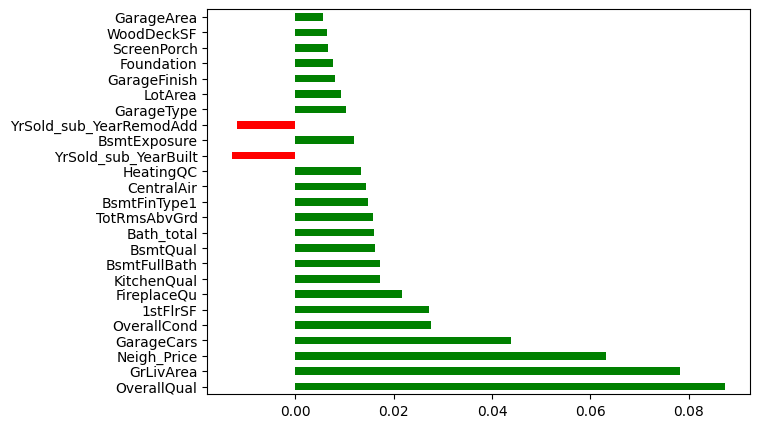

In [ ]:
plt.figure(figsize= (7, 5))
top_25_lasso.plot.barh(color= (top_25_lasso > 0).map({True: 'g', False: 'r'}))
plt.show()

In [ ]:
selected_features= len(lasso_coef[lasso_coef != 0])
print('Features selected by Lasso:', selected_features)
print('Features present in Ridge:', X_train.shape[1])

Features selected by Lasso: 33
Features present in Ridge: 76


Linearna regresija bez regularizacije, Ridge, i LASSO su ostvarili gotovo iste rezultate i na trening i na test skupu. Izgleda da nema overfittinga.

Linearna regresija i ridge koriste 76 obeležja. Sa druge strane, LASSO koristi 33 obeležja, te je ovaj model jednostavniji uz slične performanse.

No regularization - RMSE: 0.132, R²: 0.909

Ridge - RMSE: 0.135, R²: 0.905, alpha: 296

LASSO - RMSE: 0.142, R²: 0.895, alpha: 0.01

# Elastic Net regression

### Određivanje najboljeg alpha unakrsnom validacijom

In [ ]:
from sklearn.model_selection import GridSearchCV

elastic_net= ElasticNet(random_state= 42)
params_grid= {'alpha': range1}

gcv_elastic_net= GridSearchCV(estimator= elastic_net,
                        param_grid= params_grid,
                        cv=5,
                        scoring= 'neg_mean_squared_error',
                        return_train_score= True,
                        n_jobs= -1,
                        verbose= 1)
gcv_elastic_net.fit(X_train, y_train)

print("Elastic Net best alpha: ", gcv_elastic_net.best_estimator_.alpha)

Fitting 5 folds for each of 313 candidates, totalling 1565 fits
Elastic Net best alpha:  0.01


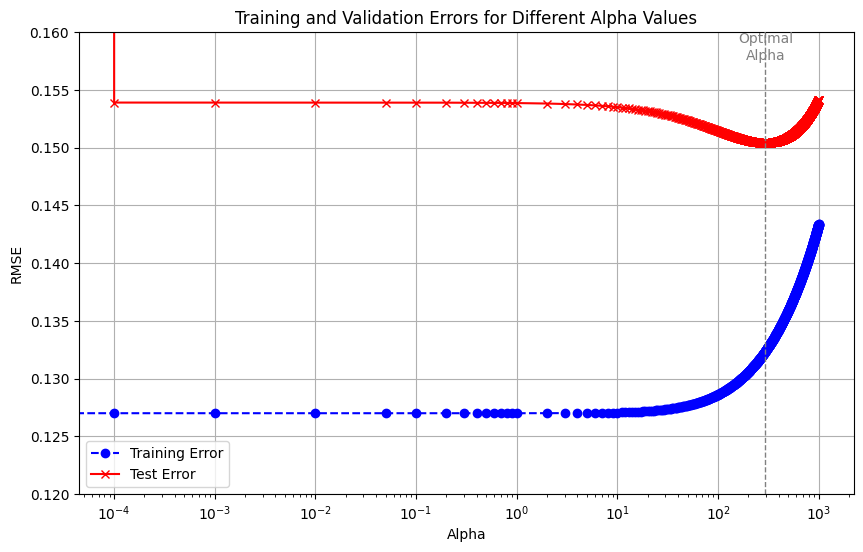

In [ ]:
plot_train_val_errors(gcv_ridge, [0.12, 0.16])

### Iscrtavanje vrednosti koeficijenata ridge modela naspram vrednosti alpha

In [ ]:
alphas_subset = np.linspace(0.001, 1000, num=10)

elastic_net_models = [ElasticNet(alpha=alpha).fit(X_train, y_train) for alpha in alphas_subset]

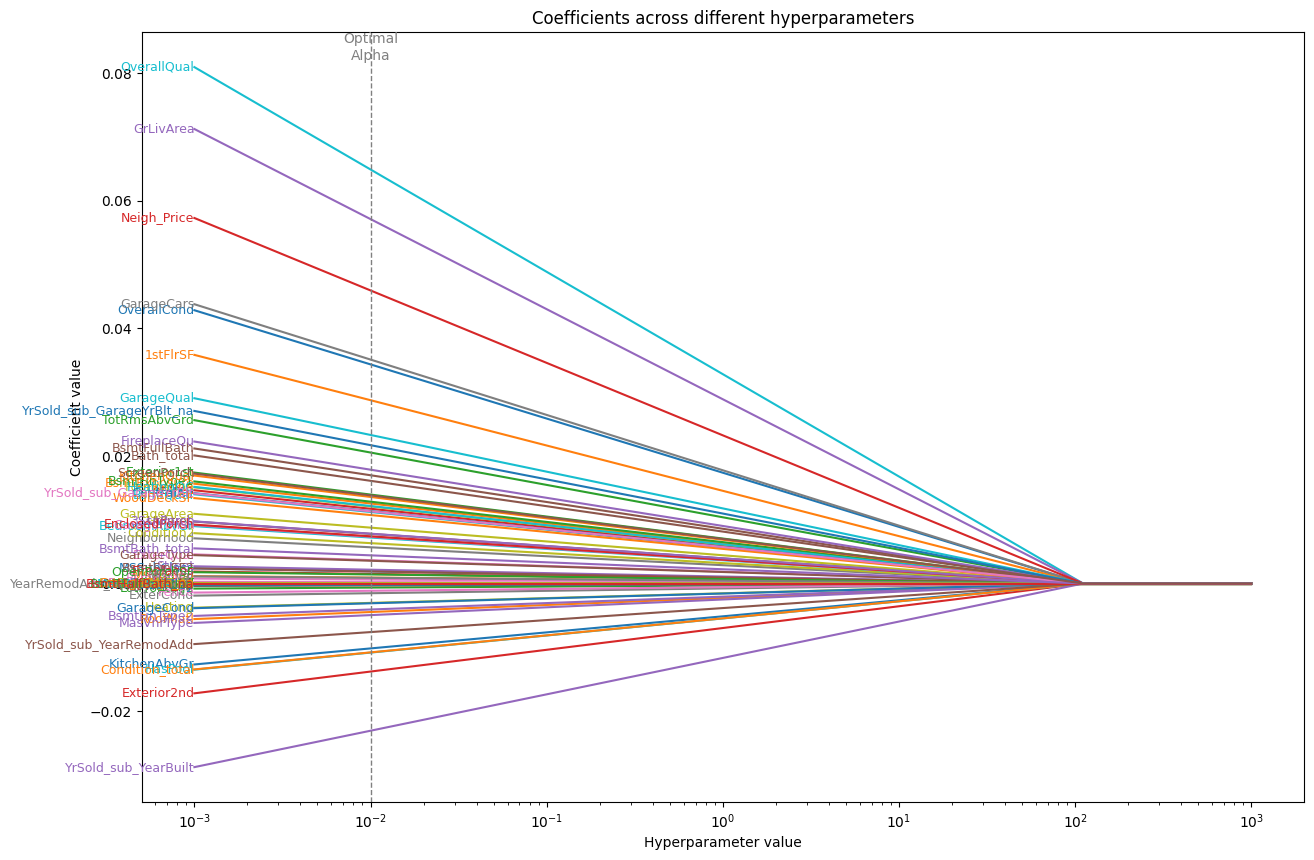

In [ ]:
plot_coefficients([elastic_net_models],
                  ['Elastic Net'],
                  alphas_subset,
                  feature_names,
                  gcv_elastic_net.best_estimator_.alpha)

### Evaluacija najboljeg Elastic Net modela na test skupu

In [ ]:
elastic_net_model= gcv_elastic_net.best_estimator_
elastic_net_model.fit(X_train, y_train)

elastic_net_rmse, elastic_net_r2 = evaluate_model(elastic_net_model, X_test, y_test)

print(f"Linear Regression - RMSE: {lin_rmse:.3f}, R²: {lin_r2:.3f}")
print(f"Ridge - RMSE: {ridge_rmse:.3f}, R²: {ridge_r2:.3f}, alpha: {gcv_ridge.best_estimator_.alpha}")
print(f"Elastic Net - RMSE: {elastic_net_rmse:.3f}, R²: {elastic_net_r2:.3f}, alpha: {gcv_elastic_net.best_estimator_.alpha}")
print(f"LASSO - RMSE: {lasso_rmse:.3f}, R²: {lasso_r2:.3f}, alpha: {gcv_lasso.best_estimator_.alpha}")

Linear Regression - RMSE: 0.132, R²: 0.909
Ridge - RMSE: 0.135, R²: 0.905, alpha: 296
Elastic Net - RMSE: 0.136, R²: 0.903, alpha: 0.01
LASSO - RMSE: 0.142, R²: 0.895, alpha: 0.01


### Najbitnija obeležja

In [ ]:
elastic_net_coef = pd.Series(elastic_net_model.coef_.flatten(), index=feature_names)
top_25_elastic_net = elastic_net_coef[abs(elastic_net_coef).nlargest(25).index]
print(top_25_elastic_net)

OverallQual                0.083109
GrLivArea                  0.073436
Neigh_Price                0.060697
GarageCars                 0.041452
OverallCond                0.035286
1stFlrSF                   0.031593
FireplaceQu                0.022488
TotRmsAbvGrd               0.020336
BsmtFullBath               0.019897
Bath_total                 0.019388
KitchenQual                0.017342
YrSold_sub_YearBuilt      -0.016139
BsmtFinType1               0.015180
BsmtQual                   0.014680
HeatingQC                  0.013978
BsmtExposure               0.013456
CentralAir                 0.013261
LotArea                    0.011881
ScreenPorch                0.011410
Foundation                 0.010967
YrSold_sub_YearRemodAdd   -0.010150
Condition_total           -0.008772
WoodDeckSF                 0.008757
KitchenAbvGr              -0.008481
GarageFinish               0.008392
dtype: float64


In [ ]:
selected_features_lasso = len(lasso_coef[lasso_coef != 0])
selected_features_elastic_net = len(elastic_net_coef[elastic_net_coef != 0])
print('Features selected by Lasso:', selected_features)
print('Features selected by Elastic Net:', selected_features_elastic_net)
print('Features present in Ridge:', X_train.shape[1])

Features selected by Lasso: 33
Features selected by Elastic Net: 39
Features present in Ridge: 76


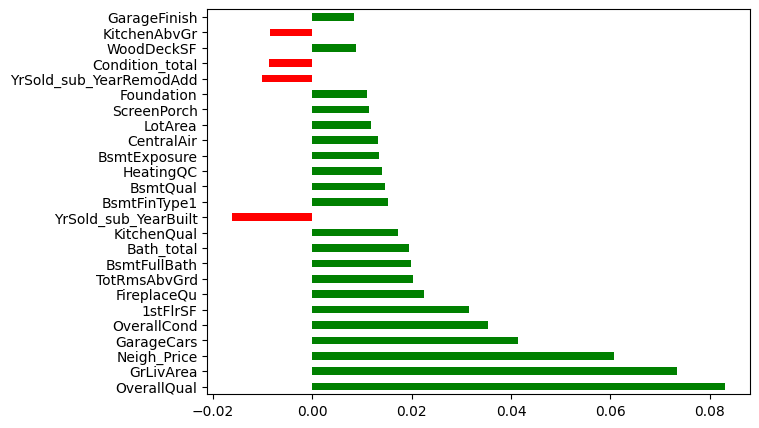

In [ ]:
plt.figure(figsize= (7, 5))
top_25_elastic_net.plot.barh(color= (top_25_elastic_net > 0).map({True: 'g', False: 'r'}))
plt.show()

Elastic Net je sa 39 obeležja postigao bolje performanse od LASSO sa 33 obeležja.

Linear Regression - RMSE: 0.132, R²: 0.909

Ridge - RMSE: 0.135, R²: 0.905, alpha: 296

Elastic Net - RMSE: 0.136, R²: 0.903, alpha: 0.01

LASSO - RMSE: 0.142, R²: 0.895, alpha: 0.01